# Sigmoid Round 2 — Bike-sharing: more bikes, or better allocation?
Human-led, AI-assisted analysis. All logic is in `model_utils.py`; this notebook runs it and records outputs.

**What this data can and cannot show.** `hour.csv`/`day.csv` are *citywide completed rentals* (Capital Bikeshare, D.C., 2011-12).
They contain no station stock, origin/destination, failed requests, fleet size or trip duration.
So we keep five quantities apart: (1) observed completed rentals, (2) predicted completed rentals,
(3) unobserved/suppressed demand (not measurable here), (4) scenario-based fleet estimates, (5) actual fleet sufficiency (not measurable here).

In [1]:
import json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
import model_utils as mu
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .3, 'font.size': 10})
C_WORK, C_NON, C_ACC = '#2a6f97', '#e07a1f', '#7a7a7a'
mu.OUT_DIR.mkdir(exist_ok=True); mu.MODEL_DIR.mkdir(exist_ok=True)
RESULTS = {}
h_raw, d = mu.load_hour(), mu.load_day()
h = mu.add_features(h_raw)
h.shape, d.shape

((17379, 27), (731, 16))

## A. Data quality checks

In [2]:
qr = mu.quality_report(h_raw, d)
qr.to_csv(mu.OUT_DIR/'data_quality_checks.csv', index=False)
qr

,check,result,note
0,hour.csv rows,17379,"17,379 per Readme"
1,day.csv rows,731,731 per Readme
2,Null values (hour / day),0 / 0,0 expected
3,Duplicate rows (hour),0,0 expected
4,"Duplicate (date, hr) keys",0,0 expected
5,cnt == casual + registered (hour),True,identity
6,Hourly sums reconcile with day.csv,True,identity
7,Expected hours (731 x 24),17544,
8,Missing hour-rows,165,hours absent from the log
9,Days with < 24 recorded hours,76,


In [3]:
hours_per_day = h_raw.groupby('dteday').size()
inc = mu.incomplete_days(h_raw)
print('Incomplete days (<20 recorded hours):', [str(x.date()) for x in inc])
print('\nRecorded hours per day (distribution):'); print(hours_per_day.value_counts().sort_index())
# Which hours go missing? Mostly low-demand night hours -> consistent with 'no rentals logged' rather than data loss
full = pd.MultiIndex.from_product([d.dteday, range(24)], names=['dteday','hr'])
missing = full.difference(pd.MultiIndex.from_frame(h_raw[['dteday','hr']]))
miss_hr = pd.Series(missing.get_level_values('hr')).value_counts().sort_index()
print('\nMissing rows by hour of day:'); print(miss_hr.to_string())
RESULTS['missing_rows'] = int(len(missing)); RESULTS['incomplete_days'] = [str(x.date()) for x in inc]

Incomplete days (<20 recorded hours): ['2011-01-18', '2011-01-26', '2011-01-27', '2011-02-22', '2011-08-27', '2011-08-28', '2012-10-29', '2012-10-30']

Recorded hours per day (distribution):
1       1
8       1
11      1
12      1
16      1
17      1
18      2
22      6
23     62
24    655
Name: count, dtype: int64

Missing rows by hour of day:
hr
0      5
1      7
2     16
3     34
4     34
5     14
6      6
7      4
8      4
9      4
10     4
11     4
12     3
13     2
14     2
15     2
16     1
17     1
18     3
19     3
20     3
21     3
22     3
23     3


**Decision (approved):** do not impute missing hours. Most are 0-6 am hours, which most likely had zero logged rentals.
Days with <20 recorded hours (incl. 2012-10-29/30, Hurricane Sandy) are flagged and excluded from hypothesis tests;
they stay in the model data because they are genuine low-demand events.
`hum==0` (22 rows) and `windspeed==0` (2,180 rows) look like missing values; tree models are robust to this, so we leave them and note it.

## A. Feature engineering and exploratory analysis

        temp_c  atemp_c  hum_pct  wind_kmh
count  17379.0  17379.0  17379.0   17379.0
mean      20.4     23.8     62.7      12.7
std        7.9      8.6     19.3       8.2
min        0.8      0.0      0.0       0.0
25%       13.9     16.7     48.0       7.0
50%       20.5     24.2     63.0      13.0
75%       27.1     31.1     78.0      17.0
max       41.0     50.0    100.0      57.0


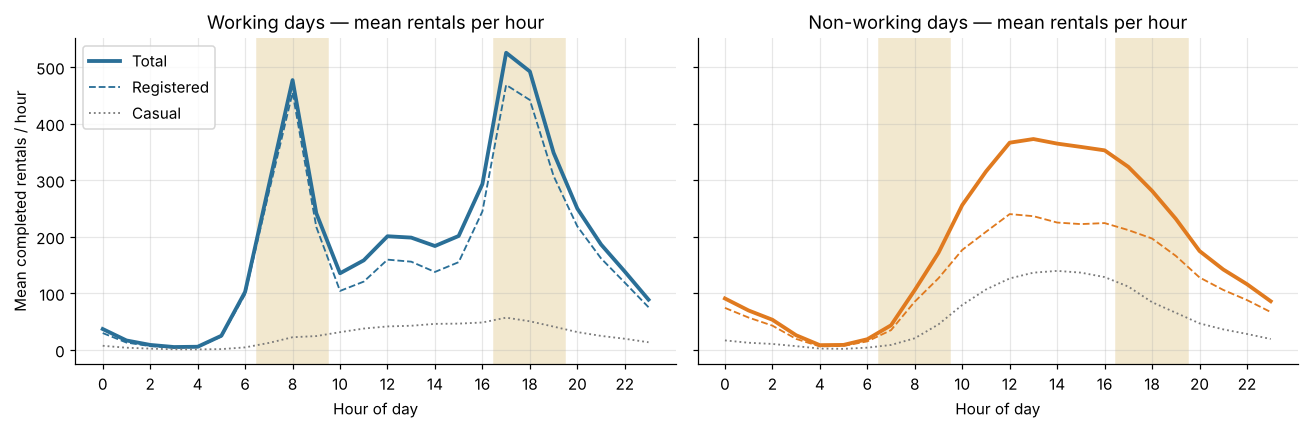

day_type  Non-working day  Working day
hr                                    
8                   106.0        477.0
13                  373.0        198.0
17                  324.0        525.0
18                  281.0        492.0


In [4]:
print(h[['temp_c','atemp_c','hum_pct','wind_kmh']].describe().round(1))
# Hourly profile by day type and user type
prof = h.groupby(['day_type','hr'])[['cnt','registered','casual']].mean()
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, dt, col in [(ax[0],'Working day',C_WORK),(ax[1],'Non-working day',C_NON)]:
    p = prof.loc[dt]
    a.plot(p.index, p.cnt, color=col, lw=2.5, label='Total')
    a.plot(p.index, p.registered, color=col, lw=1.2, ls='--', label='Registered')
    a.plot(p.index, p.casual, color=C_ACC, lw=1.2, ls=':', label='Casual')
    for x in mu.PEAK_HOURS: a.axvspan(x-.5, x+.5, color='#f2e8cf', zorder=0)
    a.set_title(f'{dt}s — mean rentals per hour'); a.set_xlabel('Hour of day'); a.set_xticks(range(0,24,2))
ax[0].set_ylabel('Mean completed rentals / hour'); ax[0].legend()
plt.tight_layout(); plt.savefig(mu.OUT_DIR/'01_hourly_profile_by_daytype.png'); plt.show()
print((prof['cnt'].unstack(0).loc[[8,13,17,18]]).round(0))

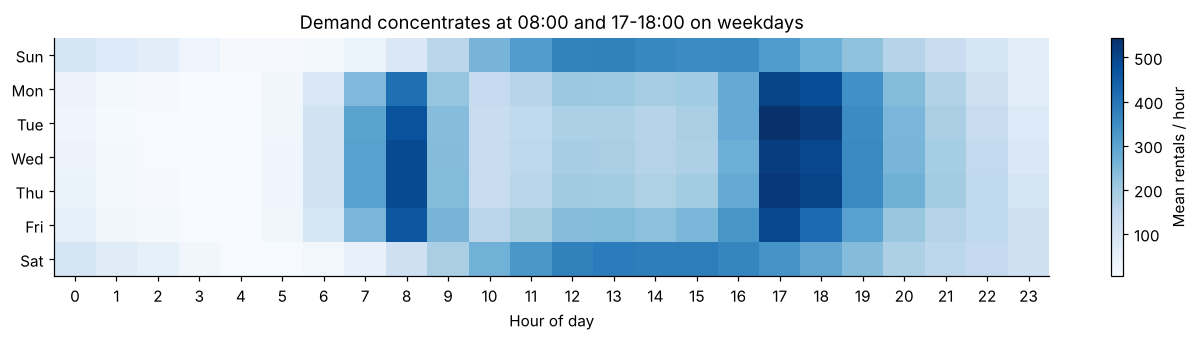

In [5]:
# Heatmap hour x weekday
pv = h.pivot_table(index='weekday', columns='hr', values='cnt', aggfunc='mean')
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(pv, aspect='auto', cmap='Blues')
ax.set_yticks(range(7)); ax.set_yticklabels(['Sun','Mon','Tue','Wed','Thu','Fri','Sat'])
ax.set_xticks(range(24)); ax.set_xlabel('Hour of day'); ax.grid(False)
plt.colorbar(im, label='Mean rentals / hour'); ax.set_title('Demand concentrates at 08:00 and 17-18:00 on weekdays')
plt.tight_layout(); plt.savefig(mu.OUT_DIR/'02_heatmap_weekday_hour.png'); plt.show()

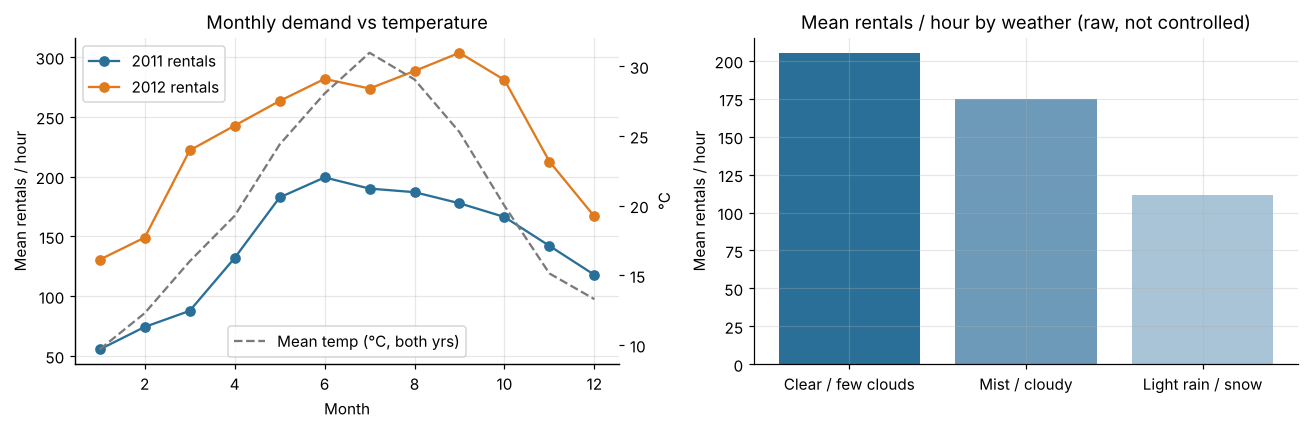

weather_label
Clear / few clouds    204.9
Mist / cloudy         175.2
Light rain / snow     111.6
Name: cnt, dtype: float64


In [6]:
# Monthly trend with temperature, and weather effect
m = h.groupby(['year','mnth']).agg(cnt=('cnt','mean'), temp=('temp_c','mean')).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for y, col in [(2011, C_WORK), (2012, C_NON)]:
    s = m[m.year==y]; ax[0].plot(s.mnth, s.cnt, marker='o', color=col, label=f'{y} rentals')
ax0b = ax[0].twinx(); s = m.groupby('mnth').temp.mean()
ax0b.plot(s.index, s.values, color=C_ACC, ls='--', label='Mean temp (°C, both yrs)'); ax0b.set_ylabel('°C'); ax0b.grid(False)
ax[0].set_title('Monthly demand vs temperature'); ax[0].set_xlabel('Month'); ax[0].set_ylabel('Mean rentals / hour')
ax[0].legend(loc='upper left'); ax0b.legend(loc='lower center')
w = h[h.weathersit<=3].groupby('weather_label').cnt.mean().reindex(list(mu.WEATHER_LABELS.values())[:3])
ax[1].bar(w.index, w.values, color=[C_WORK, '#6c9ab8', '#a9c4d6'])
ax[1].set_title('Mean rentals / hour by weather (raw, not controlled)'); ax[1].set_ylabel('Mean rentals / hour')
plt.tight_layout(); plt.savefig(mu.OUT_DIR/'03_monthly_and_weather.png'); plt.show()
print(w.round(1)); RESULTS['yearly_totals'] = h.groupby('year').cnt.sum().to_dict()

In [7]:
# How peaky is demand? (relevant to fleet sizing)
pct = h.groupby('year').cnt.quantile([.5,.9,.95,.99]).unstack().round(0)
pct['max'] = h.groupby('year').cnt.max(); print(pct)
RESULTS['hourly_percentiles_by_year'] = pct.to_dict(orient='index')

        0.5    0.9   0.95   0.99  max
year                                 
2011  109.0  346.0  420.0  554.0  651
2012  191.0  546.0  662.0  835.0  977


## B. Hypothesis H1 — commuter-hour demand
**H0:** the share of a day's rentals that fall in the commute windows (07-09 & 17-19) is the same on working and non-working days.
**H1:** the share is higher on working days.

*Design:* unit = **day** (hours within a day are correlated, so hourly rows would overstate significance). Incomplete days excluded.
One-sided Mann-Whitney U (no normality assumption), rank-biserial effect size, 95% bootstrap CI of the mean difference, repeated within each season as a robustness check.

*What it can and cannot tell us:* it establishes **when** demand concentrates (a rebalancing deadline). It **cannot** show residential→office movement — that needs origin/destination trip data.

In [8]:
h1 = mu.test_h1(h)
for k in ['n_working_days','n_nonworking_days','mean_peak_share_working','mean_peak_share_nonworking',
          'U','p_value','rank_biserial','hodges_lehmann_shift','hodges_lehmann_ci95','mean_diff_ci95',
          'permutation_p_one_sided','registered_share_at_peak_working','registered_share_at_peak_nonworking']:
    print(f'{k:40s} {h1[k]}')
h1['by_season'].round(4)

n_working_days                           494
n_nonworking_days                        229
mean_peak_share_working                  0.5174406359429762
mean_peak_share_nonworking               0.26006561779479065
U                                        112531.0
p_value                                  4.096573928632997e-102
rank_biserial                            0.989480755971218
hodges_lehmann_shift                     0.2620975586623785
hodges_lehmann_ci95                      (0.25723807196312126, 0.2679063361104857)
mean_diff_ci95                           (0.25034835979393244, 0.2641043946167627)
permutation_p_one_sided                  0.0
registered_share_at_peak_working         0.9175893830645575
registered_share_at_peak_nonworking      0.7406835824457336


,season,working_mean,nonworking_mean,n_working,n_nonworking,p_value,rank_biserial
0,Spring,0.5280,0.2396,116,61,0.0,0.9958
1,Summer,0.5154,0.2788,128,56,0.0,0.9872
2,Fall,0.5119,0.2700,131,55,0.0,1.0000
3,Winter,0.5154,0.2541,119,57,0.0,0.9779


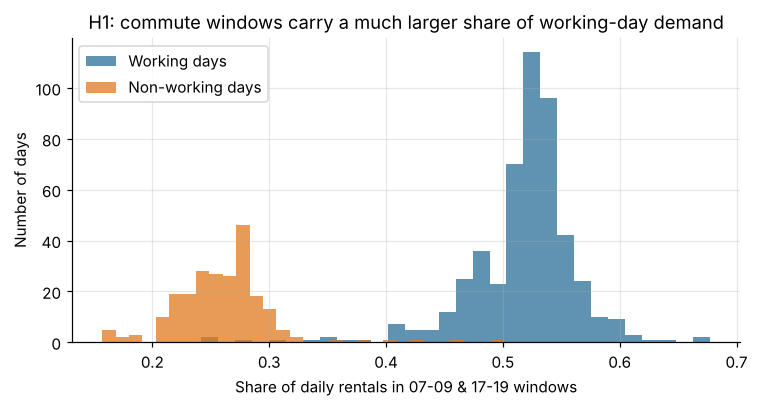

In [9]:
t = h1['daily_table']
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(t[t.workingday==1].peak_share, bins=30, alpha=.75, color=C_WORK, label='Working days')
ax.hist(t[t.workingday==0].peak_share, bins=30, alpha=.75, color=C_NON, label='Non-working days')
ax.set_xlabel('Share of daily rentals in 07-09 & 17-19 windows'); ax.set_ylabel('Number of days'); ax.legend()
ax.set_title('H1: commute windows carry a much larger share of working-day demand')
plt.tight_layout(); plt.savefig(mu.OUT_DIR/'04_h1_peak_share.png'); plt.show()
RESULTS['H1'] = {k: h1[k] for k in h1 if k not in ('by_season','daily_table')}
RESULTS['H1']['by_season'] = h1['by_season'].to_dict(orient='records')

## B. Hypothesis H3 — is the July dip heat, not rain?
In Round 1 the July dip was tentatively attributed to a monsoon. D.C. does not have a monsoon, so we test the alternative: heat.

**H0:** on dry summer days (Jun-Aug), demand on hot days (daily max ≥ 32 °C) is the same as on other summer days.
**H1:** hot days have lower demand.

*Design:* unit = day; wet days (weathersit ≥ 3) and incomplete days excluded; daily rentals divided by the mean of the same (year × day-type) group so 2011→2012 growth and the commute effect are removed. One-sided Mann-Whitney + Spearman correlation.
*Limitation:* temperature and humidity move together, so this tests heat-and-humidity together, not heat alone; small sample.

**Estimands (corrected after review).** An earlier version paired a one-sided Mann-Whitney p-value (a *rank* comparison) with a two-sided 95% bootstrap CI of the *mean* difference.
Those answer different questions, and a one-sided 5% test corresponds to a two-sided 90% interval. We now report matched pairs:
- rank-based: Mann-Whitney one-sided p ↔ Hodges-Lehmann location shift + bootstrap CI;
- mean-based: one-sided permutation p on the mean difference ↔ bootstrap CI of the mean difference (95% and 90%).

In [10]:
h3 = mu.test_h3(h, d)
for k in ['n_hot_days','n_other_days','median_relative_demand_hot','median_relative_demand_other',
          'p_value','rank_biserial','hodges_lehmann_shift','hodges_lehmann_ci95',
          'mean_diff','permutation_p_one_sided','mean_diff_ci95','mean_diff_ci90',
          'spearman_rho_temp_vs_demand','spearman_p','spearman_rho_temp_vs_humidity']:
    print(f'{k:35s} {h3[k]}')
h3['monthly_context'].round(3)

n_hot_days                          126
n_other_days                        55
median_relative_demand_hot          1.0024870700125228
median_relative_demand_other        1.0667680031676046
p_value                             0.003429767839216283
rank_biserial                       0.25310245310245305
hodges_lehmann_shift                -0.05031538655608869
hodges_lehmann_ci95                 (-0.08431030673969502, -0.012547564036467836)
mean_diff                           -0.0370127706426715
permutation_p_one_sided             0.0321
mean_diff_ci95                      (-0.08032056774019278, 0.00674055160189345)
mean_diff_ci90                      (-0.07225049779371126, -0.0007112834288538446)
spearman_rho_temp_vs_demand         -0.3477136727142265
spearman_p                          1.6177712347789805e-06
spearman_rho_temp_vs_humidity       -0.18926510292954915


,year,mnth,mean_hourly_cnt,mean_temp_c,share_rain_snow_hours
4,2011,5,182.555,23.666,0.087
5,2011,6,199.322,28.416,0.047
6,2011,7,189.974,31.102,0.020
7,2011,8,186.992,28.928,0.066
8,2011,9,177.710,25.130,0.139
16,2012,5,263.259,25.107,0.105
17,2012,6,281.708,27.680,0.053
18,2012,7,273.665,30.847,0.063
19,2012,8,288.310,29.184,0.052
20,2012,9,303.574,25.423,0.061


**Exploratory sensitivity (post-hoc, NOT confirmatory).** The pre-specified threshold is 32 °C (approved decision: keep it).
The thresholds below were examined *after* seeing the scatter plot, so their smaller p-values must not be read as stronger evidence.

In [11]:
sens = mu.h3_sensitivity(h, d); sens.to_csv(mu.OUT_DIR/'h3_threshold_sensitivity_EXPLORATORY.csv', index=False)
RESULTS['H3_sensitivity_exploratory'] = sens.to_dict(orient='records'); sens.round(4)

,threshold_c,status,n_hot,n_other,HL_shift,MW_p_one_sided,mean_diff,mean_diff_ci95,perm_p_one_sided
0,32,pre-specified,126,55,-0.0503,0.0034,-0.0370,"(-0.08032056774019278, 0.00674055160189345)",0.0321
1,34,exploratory (post-hoc),72,109,-0.0781,0.0000,-0.0737,"(-0.10705134038067217, -0.03872142897378813)",0.0000
2,35,exploratory (post-hoc),57,124,-0.0967,0.0000,-0.0937,"(-0.12826678160226124, -0.05974107859463788)",0.0000
3,36,exploratory (post-hoc),41,140,-0.1146,0.0000,-0.1102,"(-0.14867967192782852, -0.07238216901243229)",0.0000


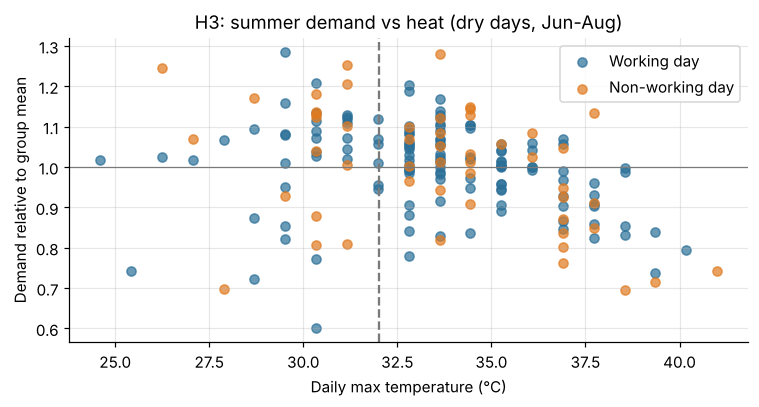

In [12]:
t3 = h3['daily_table']
fig, ax = plt.subplots(figsize=(7, 3.8))
for wd, col, lab in [(1, C_WORK, 'Working day'), (0, C_NON, 'Non-working day')]:
    s = t3[t3.workingday==wd]; ax.scatter(s.max_temp_c, s.relative_demand, color=col, alpha=.7, label=lab)
ax.axvline(h3['hot_threshold_c'], color=C_ACC, ls='--'); ax.axhline(1, color=C_ACC, lw=.8)
ax.set_xlabel('Daily max temperature (°C)'); ax.set_ylabel('Demand relative to group mean')
ax.set_title('H3: summer demand vs heat (dry days, Jun-Aug)'); ax.legend()
plt.tight_layout(); plt.savefig(mu.OUT_DIR/'05_h3_heat.png'); plt.show()
RESULTS['H3'] = {k: h3[k] for k in h3 if k not in ('monthly_context','daily_table')}
RESULTS['H3']['monthly_context'] = h3['monthly_context'].to_dict(orient='records')

## C. Demand model — chronological evaluation
Train: 2011-01-01 → 2012-06-30. Test: 2012-07-01 → 2012-12-31 (summer peak, July heat, winter, Sandy).
Features: calendar + recorded weather (= assumes a perfect weather forecast; acceptable for planning scenarios).
Excluded: `casual`, `registered` (sum to target), `instant`, lag features.
No scaling/encoding is fitted on the data, so no preprocessing leakage. Target modelled as log1p(cnt).

In [13]:
train, test = mu.chrono_split(h)
print('train', train.dteday.min().date(), '->', train.dteday.max().date(), len(train))
print('test ', test.dteday.min().date(), '->', test.dteday.max().date(), len(test))
base = mu.SeasonalBaseline().fit(train)
preds = {'Seasonal baseline': base.predict(test)}
models = {}
for name, mdl in mu.make_models().items():
    models[name] = mu.fit_log_model(mdl, train)
    preds[name] = mu.predict_log_model(models[name], test)
metrics = pd.DataFrame({n: mu.evaluate(test.cnt, p, test.is_peak) for n, p in preds.items()}).T.round(2)
metrics.to_csv(mu.OUT_DIR/'model_metrics_test_2012H2.csv'); print('Baseline growth factor', round(base.growth_, 3))
metrics

train 2011-01-01 -> 2012-06-30 13003
test  2012-07-01 -> 2012-12-31 4376


Baseline growth factor 1.743


,MAE,RMSE,R2,Peak-hour MAE,Peak-hour bias (pred-actual)
Seasonal baseline,56.19,92.62,0.82,87.91,46.92
HistGradientBoosting,44.52,70.98,0.90,82.76,-50.97
RandomForest,49.94,78.93,0.87,87.75,-49.86


Median absolute % error on daily totals: {'Seasonal baseline': np.float64(11.9), 'HistGradientBoosting': np.float64(12.8), 'RandomForest': np.float64(13.5)}


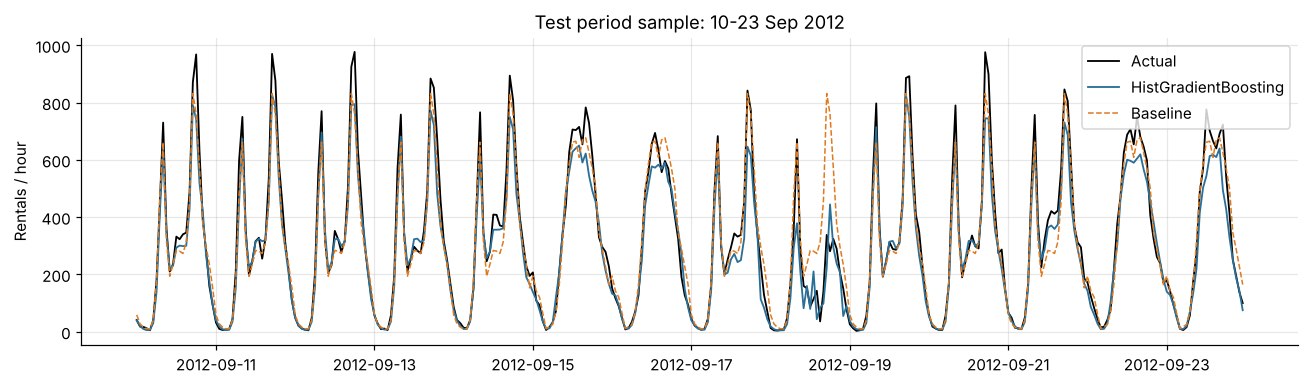

In [14]:
# Daily-level accuracy (what a planner sees) and a sample fortnight
daily = test.assign(**{n: p for n, p in preds.items()}).groupby('dteday')[['cnt']+list(preds)].sum()
dm = {n: (np.abs(daily[n]-daily.cnt)/daily.cnt).median()*100 for n in preds}
print('Median absolute % error on daily totals:', {k: round(v,1) for k,v in dm.items()})
RESULTS['daily_median_ape_pct'] = dm
best = metrics['MAE'].idxmin(); RESULTS['best_model'] = best; RESULTS['metrics'] = metrics.to_dict(orient='index')
win = test[(test.dteday>='2012-09-10')&(test.dteday<'2012-09-24')]
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(win.dteday + pd.to_timedelta(win.hr, unit='h'), win.cnt, color='black', lw=1.2, label='Actual')
idx = win.index - test.index[0]
ax.plot(win.dteday + pd.to_timedelta(win.hr, unit='h'), preds[best][test.index.get_indexer(win.index)], color=C_WORK, lw=1.2, label=best)
ax.plot(win.dteday + pd.to_timedelta(win.hr, unit='h'), preds['Seasonal baseline'][test.index.get_indexer(win.index)], color=C_NON, lw=1, ls='--', label='Baseline')
ax.set_title('Test period sample: 10-23 Sep 2012'); ax.set_ylabel('Rentals / hour'); ax.legend()
plt.tight_layout(); plt.savefig(mu.OUT_DIR/'06_forecast_sample.png'); plt.show()

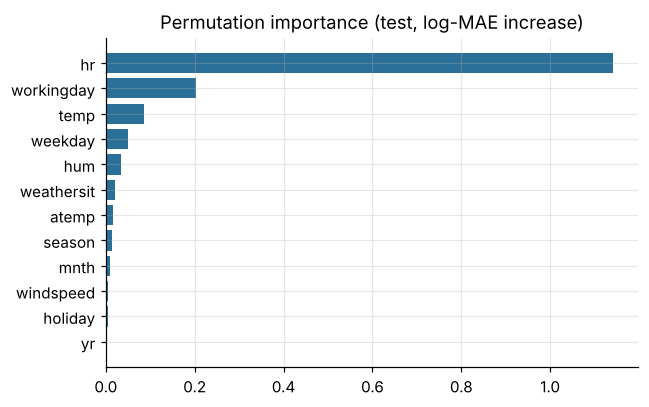

hr            1.141
workingday    0.204
temp          0.086
weekday       0.049
hum           0.034
weathersit    0.020
atemp         0.016
season        0.014
mnth          0.009
windspeed     0.005
holiday       0.004
yr            0.000
dtype: float64


In [15]:
# Which inputs matter? (permutation importance on the test set, best model)
from sklearn.inspection import permutation_importance
mdl = models[best] if best in models else models['HistGradientBoosting']
pi = permutation_importance(mdl, test[mu.FEATURES], np.log1p(test.cnt), n_repeats=5, random_state=42, scoring='neg_mean_absolute_error')
imp = pd.Series(pi.importances_mean, index=mu.FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6, 3.8)); ax.barh(imp.index, imp.values, color=C_WORK)
ax.set_title('Permutation importance (test, log-MAE increase)'); plt.tight_layout()
plt.savefig(mu.OUT_DIR/'07_feature_importance.png'); plt.show(); print(imp.sort_values(ascending=False).round(3))

In [16]:
# Refit the chosen ML model on ALL data for the prototype (evaluation above used the held-out split)
final_name = best if best in models else 'HistGradientBoosting'
final = mu.fit_log_model(mu.make_models()[final_name], h)
joblib.dump({'model': final, 'features': mu.FEATURES, 'name': final_name,
             'trained_on': '2011-01-01..2012-12-31', 'note': 'log1p target; evaluate via notebook split'},
            mu.MODEL_DIR/'demand_model.joblib')
joblib.dump(base, mu.MODEL_DIR/'seasonal_baseline.joblib')
print('saved', final_name)

saved HistGradientBoosting


## C. Scenario-based fleet estimate
`fleet = demand/hr × trip duration (h) × spatial buffer ÷ (1 − maintenance share)` — Little's law plus two operational allowances.
Every input except demand is an **assumption** (no trip-duration, fleet or station data in this dataset). Defaults (approved): p95 demand, 20-min trips, 10 % maintenance, 2× spatial buffer.
The 2,000-bike fleet is the *fictional* Round 1 figure, used only as a reference line.

In [17]:
ref_period = h[h.year==2012]
demand_levels = {
  'Observed 2012 p90': ref_period.cnt.quantile(.90),
  'Observed 2012 p95 (default)': ref_period.cnt.quantile(.95),
  'Observed 2012 p99': ref_period.cnt.quantile(.99),
  'Observed max hour': h.cnt.max(),
  'Predicted p95, test period': np.percentile(preds[best], 95),
}
rows = []
for lab, dem in demand_levels.items():
    r = mu.fleet_required(dem); r['demand_scenario'] = lab; rows.append(r)
fleet = pd.DataFrame(rows).set_index('demand_scenario').round(1); fleet.to_csv(mu.OUT_DIR/'fleet_scenarios.csv'); print(fleet)
grid = mu.fleet_grid(demand_levels['Observed 2012 p95 (default)']); grid.to_csv(mu.OUT_DIR/'fleet_sensitivity_grid.csv')
print('\nSensitivity (p95 demand, 10% maintenance): rows = trip minutes, cols = spatial buffer'); print(grid)
RESULTS['fleet_scenarios'] = fleet.to_dict(orient='index'); RESULTS['fleet_grid'] = grid.to_dict()

                             hourly_demand  trip_minutes  maintenance_share  \
demand_scenario                                                               
Observed 2012 p90                    546.0            20                0.1   
Observed 2012 p95 (default)          662.4            20                0.1   
Observed 2012 p99                    835.0            20                0.1   
Observed max hour                    977.0            20                0.1   
Predicted p95, test period           602.5            20                0.1   

                             spatial_buffer  bikes_in_motion  \
demand_scenario                                                
Observed 2012 p90                       2.0            182.0   
Observed 2012 p95 (default)             2.0            220.8   
Observed 2012 p99                       2.0            278.3   
Observed max hour                       2.0            325.7   
Predicted p95, test period              2.0            200.8  

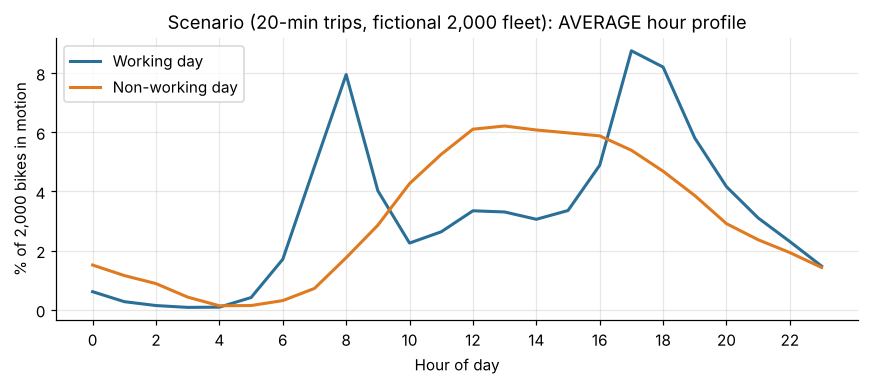

Mean of busiest hour-of-day (working days, 17:00, both years)    8.8% of 2,000 bikes in motion
Observed 2012 p95 hour                                          11.0% of 2,000 bikes in motion
Observed maximum hour (2012)                                    16.3% of 2,000 bikes in motion


In [18]:
# Utilisation view: with the fictional 2,000-bike fleet, what share is riding at once?
FICTIONAL_FLEET = 2000
util = h.groupby(['day_type','hr']).cnt.mean().unstack(0) * 20/60 / FICTIONAL_FLEET * 100
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(util.index, util['Working day'], color=C_WORK, lw=2, label='Working day')
ax.plot(util.index, util['Non-working day'], color=C_NON, lw=2, label='Non-working day')
ax.set_ylabel('% of 2,000 bikes in motion'); ax.set_xlabel('Hour of day'); ax.set_xticks(range(0,24,2)); ax.legend()
ax.set_title('Scenario (20-min trips, fictional 2,000 fleet): AVERAGE hour profile')
plt.tight_layout(); plt.savefig(mu.OUT_DIR/'08_utilisation_scenario.png'); plt.show()
# Three DIFFERENT statistics -- do not mix them up (corrected after review):
ref = mu.observed_demand_reference(h)
pct_in_motion = {
  'Mean of busiest hour-of-day (working days, 17:00, both years)': util.max().max(),
  'Observed 2012 p95 hour': ref['p95']*20/60/FICTIONAL_FLEET*100,
  'Observed maximum hour (2012)': ref['max']*20/60/FICTIONAL_FLEET*100,
}
for k, v in pct_in_motion.items(): print(f'{k:62s} {v:5.1f}% of 2,000 bikes in motion')
RESULTS['pct_in_motion_2000_20min'] = pct_in_motion

**Clarification.** 8.8% is the *average* 17:00 working-day hour (mean 525 rentals). 11.0% is the 2012 *95th-percentile* hour (662 rentals = 221 bikes in motion). 16.3% is the single busiest hour (977).
They are different statistics; none of them says whether the *right stations* had bikes.

### Fleet scenario driven by the ML forecast
The calculator accepts **predicted** hourly rentals from the trained model as input. Observed percentiles stay alongside as a historical reference.
Because the model under-predicts peak hours on the test period, forecast-driven estimates lean low.

In [19]:
# Forecast-driven scenario on the held-out test window, using the model trained only on data up to 2012-06-30
pred_hgb = preds['HistGradientBoosting']
fc_rows = {
  'ML forecast: max predicted hour (2012-H2)': mu.fleet_from_forecast(pred_hgb),
  'ML forecast: p95 of predicted hours (2012-H2)': mu.fleet_from_forecast(pred_hgb, percentile=95),
  'Observed reference: 2012-H2 p95 (actual)': mu.fleet_required(np.percentile(test.cnt, 95)),
  'Observed reference: 2012-H2 max (actual)': mu.fleet_required(test.cnt.max()),
}
fc = pd.DataFrame(fc_rows).T[['hourly_demand','bikes_in_motion','bikes_positioned','fleet_required']].astype(float).round(1)
fc.to_csv(mu.OUT_DIR/'fleet_forecast_vs_observed.csv'); RESULTS['fleet_forecast_vs_observed'] = fc.to_dict(orient='index'); fc

,hourly_demand,bikes_in_motion,bikes_positioned,fleet_required
ML forecast: max predicted hour (2012-H2),827.1,275.7,551.4,613.0
ML forecast: p95 of predicted hours (2012-H2),602.5,200.8,401.6,447.0
Observed reference: 2012-H2 p95 (actual),702.2,234.1,468.2,521.0
Observed reference: 2012-H2 max (actual),977.0,325.7,651.3,724.0


## Conclusions (human decision, Checkpoint 2)
- **H1 supported:** commute windows carry about twice the share of daily rentals on working days. This tells us *when* bikes must be in place, not *where*.
- **H3:** at the pre-specified 32 °C threshold the evidence is modest (see matched estimands above); higher thresholds look stronger but are exploratory.
  Rain does not explain July: July 2011 had the fewest rain/snow hours of the summer.
- **Model:** HistGradientBoosting is the primary hourly model (best MAE/RMSE/R²) but under-predicts peaks by ~51 rentals/hr on 2012-H2.
- **Fleet:** under the stated assumptions, scenario estimates are far below the fictional 2,000 bikes. These are **scenario estimates, not verified fleet requirements**.
- **Recommendation (Aditya):** investigate forecast-guided redistribution and fleet-health improvements *before* buying bikes, run as an **operational pilot to validate**.
  Redistribution is not proven to be the root cause without station-level availability and unmet-demand data; suggested timings (finish rebalancing before ~07:00 and ~16:30 on working days) are *trial scheduling ideas*.

In [20]:
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, pd.Timestamp): return str(o.date())
    return o
json.dump(_clean(RESULTS), open(mu.OUT_DIR/'results.json','w'), indent=2); print('results.json written')

results.json written
